# CS4451 & CS9548: Foundations of Machine Learning — Assignment 1

**Due:** 23:59, October 22, 2026  
**Name:** Issar Manknojiya  **Student #:** 251366740

### Contents
| Part | Topic | Points |
|---|---|---|
| [1](#1-refreshing-mathematics) | Refreshing Mathematics | 25 |
| [2](#2-linear-and-polynomial-regression) | Linear and Polynomial Regression | 50 |
| [3](#3-regularization-and-cross-validation) | Regularization and Cross-Validation | 25 |

## 0. Setup
Imports, data loading, and helpers shared by Parts 2 and 3.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.figsize": (6, 4), "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

In [ ]:
xtr = np.loadtxt("hw1xtr.dat")   # training features
ytr = np.loadtxt("hw1ytr.dat")   # training targets
xte = np.loadtxt("hw1xte.dat")   # test features
yte = np.loadtxt("hw1yte.dat")   # test targets

print("train:", xtr.shape, ytr.shape, "| test:", xte.shape, yte.shape)

train: (40,) (40,) | test: (20,) (20,)


In [13]:
def design_matrix(x, order):
    '''Return the m x (order+1) matrix [1, x, x^2, ..., x^order].'''
    return np.vander(x, order + 1, increasing=True)


def fit_linear_regression(X, y):
    '''Least-squares weights using the closed-form solution from Lecture 3.'''
    return np.linalg.solve(X.T @ X, X.T @ y)   # (X^T X)^-1 X^T y


def fit_ridge(X, y, lam):
    '''l2-regularized weights (Lecture 4, p.12). The bias term w0 is NOT penalized.'''
    # TODO
    raise NotImplementedError


def avg_error(X, y, w):
    '''Average error, Eq. (1):  (1/m) * sum_i (w^T x_i - y_i)^2'''
    return np.mean((X @ w - y) ** 2)


def plot_fit(x, y, w, order, title="", label="data"):
    '''Scatter the data and overlay the fitted polynomial curve.'''
    grid = np.linspace(0, 4, 200)
    plt.figure()
    plt.scatter(x, y, label=label)
    plt.plot(grid, design_matrix(grid, order) @ w, "r", label=f"order {order} fit")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.legend()
    plt.show()

---
## 1. Refreshing Mathematics
**[25 points]**

Let $\mathbf{w}\in\mathbb{R}^n$ be an $n$-dimensional column vector and $f(\mathbf{w})\in\mathbb{R}$ a function of $\mathbf{w}$.
As defined in Lecture 2, $\nabla f(\mathbf{w})\in\mathbb{R}^n$ is the gradient and $H\in\mathbb{R}^{n\times n}$ is the Hessian of $f$ with respect to $\mathbf{w}$.

### 1(a) &nbsp; [5 points]
Let $\mathbf{a},\mathbf{b}\in\mathbb{R}^n$ and let $\mathbf{a}\circ\mathbf{b}$ be the element-wise (Hadamard) product.
Let $f(\mathbf{w}) = \mathbf{a}^\top(\mathbf{w}\circ\mathbf{b})$. Compute $\nabla f(\mathbf{w})$ **using the definition of gradient**.

**Answer:**

_TODO_

### 1(b) &nbsp; [5 points]
Let $f(\mathbf{w}) = \operatorname{tr}(B\mathbf{w}\mathbf{w}^\top A)$, where $A,B\in\mathbb{R}^{n\times n}$ are square matrices.
Using the definition of gradient, compute $\nabla f(\mathbf{w})$.

**Answer:**

_TODO_

### 1(c) &nbsp; [5 points]
Let $f(\mathbf{w}) = \operatorname{tr}(B\mathbf{w}\mathbf{w}^\top A)$. Compute the Hessian $H$ of $f$ with respect to $\mathbf{w}$ **using the definition**.

**Answer:**

_TODO_

### 1(d) &nbsp; [5 points]
If $A=\begin{pmatrix}1&-2\\-2&6\end{pmatrix}$ and $B=\begin{pmatrix}2&-3\\-3&2\end{pmatrix}$, is $f(\mathbf{w})$ a convex function?
*(Hint: use Python/Matlab/R.)*

In [ ]:
A = np.array([[1, -2], [-2, 6]])
B = np.array([[2, -3], [-3, 2]])

# TODO:

**Answer:**

_TODO_

### 1(e) &nbsp; [5 points]
With the sigmoid $\sigma(a)=\dfrac{1}{1+e^{-a}}$ from Lecture 5, let $f(\mathbf{w}) = \log\sigma(\mathbf{w}^\top\mathbf{x})$ (natural log).
Compute $\nabla f(\mathbf{w})$ using the definition of gradient.

**Answer:**

_TODO_

---
## 2. Linear and Polynomial Regression
**[50 points]**

Implement linear and polynomial regression in any language of your choice. Training set: `hw1xtr.dat` (features), `hw1ytr.dat` (outputs). Test set: `hw1xte.dat`, `hw1yte.dat`.

Average error used throughout (Eq. 1):
$$\text{err} = \frac{1}{m}\sum_{i=1}^{m}\left(\mathbf{w}^\top\mathbf{x}_i - y_i\right)^2$$

### 2(a) &nbsp; [5 points]
Load the training data and plot it on one graph. Load the test data and plot it on another graph.

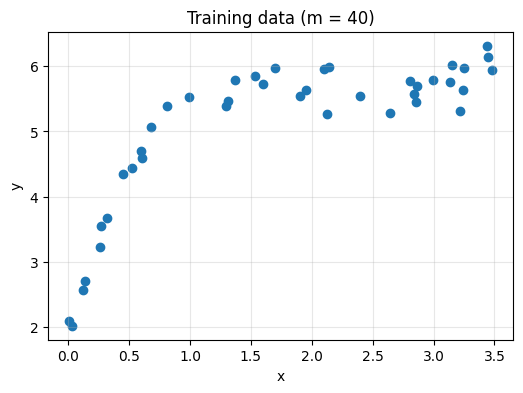

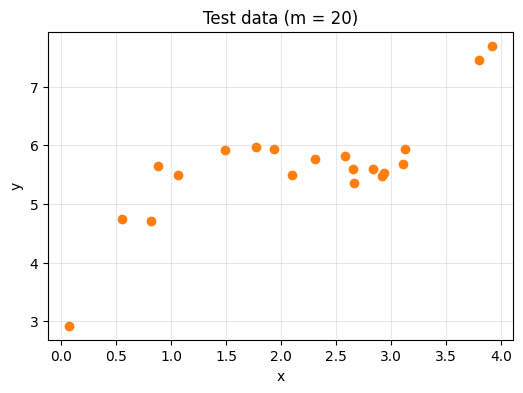

In [15]:
# Training data: its own figure
plt.figure()
plt.scatter(xtr, ytr, color="tab:blue")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Training data (m = 40)")
plt.show()

# Test data: a separate figure
plt.figure()
plt.scatter(xte, yte, color="tab:orange")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Test data (m = 20)")
plt.show()


### 2(b) &nbsp; [10 points]
Add a column of 1's to the features and use the linear regression formula from Lecture 3 to obtain a 2-dimensional weight vector.
Plot the regression line **and** the training data on the same graph. Report the average training error using Eq. (1).

weights [w0, w1]: [3.7138 0.7666]
average training error: 0.5085888601660319


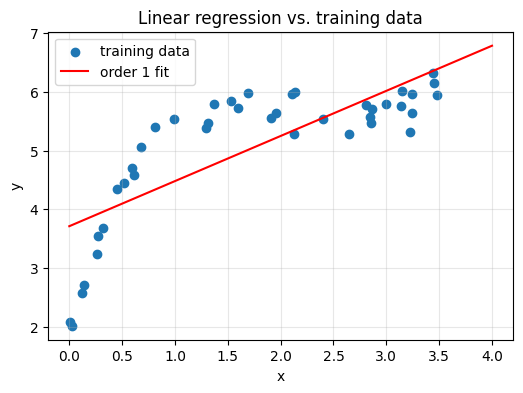

In [16]:
order = 1

Xtr = design_matrix(xtr, order)        # column of 1s + x
w1 = fit_linear_regression(Xtr, ytr)   # 2-dimensional weight vector [w0, w1]
train_err1 = avg_error(Xtr, ytr, w1)

print("weights [w0, w1]:", w1)
print("average training error:", train_err1)

plot_fit(xtr, ytr, w1, order, title="Linear regression vs. training data", label="training data")

### 2(c) &nbsp; [5 points]
Plot the regression line **and** the test data on the same graph. Report the average test error using Eq. (1).

average test error: 0.44391185790774934


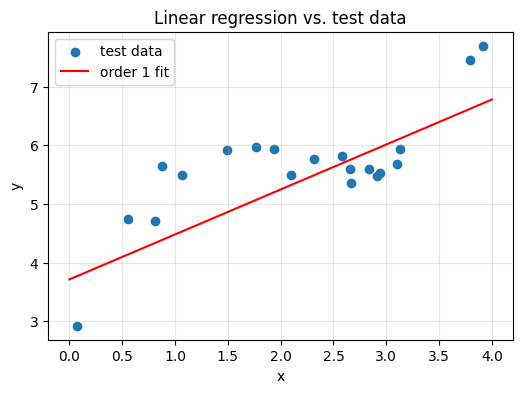

In [17]:
Xte = design_matrix(xte, 1)
test_err1 = avg_error(Xte, yte, w1)    # weights come from the TRAINING fit in 2(b)

print("average test error:", test_err1)

plot_fit(xte, yte, w1, 1, title="Linear regression vs. test data", label="test data")

**Answer (2b, 2c):**

Fitted line: $\hat y = 3.7138 + 0.7666\,x$

| Model | Train error | Test error |
|---|---|---|
| Linear (order 1) | 0.5086 | 0.4439 |

The data is visibly curved, so a straight line underfits: both errors are large and the line misses the shape of the data.

### 2(d) &nbsp; [10 points]
Implement **2nd-order** polynomial regression by adding the feature $x^2$. Repeat (b) and (c).
Compare training and test error. Is it a better fit than linear regression?

weights: [ 2.7794  2.6913 -0.5514]
order 2: train error = 0.2010,  test error = 0.8533


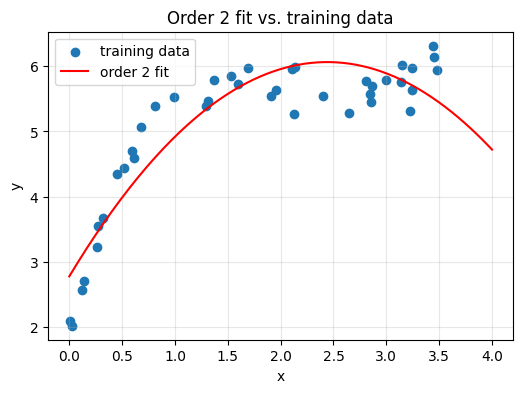

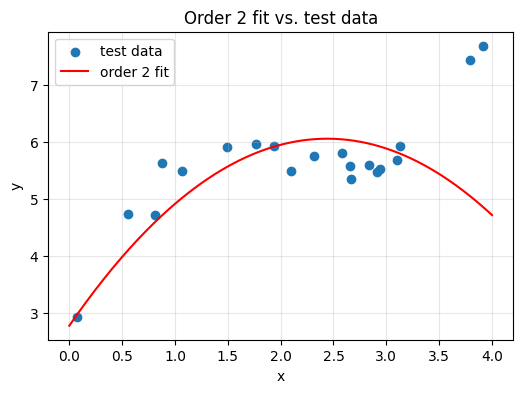

In [18]:
order = 2

Xtr, Xte = design_matrix(xtr, order), design_matrix(xte, order)
w2 = fit_linear_regression(Xtr, ytr)           # fit on TRAINING data only
train_err2 = avg_error(Xtr, ytr, w2)
test_err2 = avg_error(Xte, yte, w2)

print("weights:", w2)
print(f"order 2: train error = {train_err2:.4f},  test error = {test_err2:.4f}")

plot_fit(xtr, ytr, w2, order, title="Order 2 fit vs. training data", label="training data")
plot_fit(xte, yte, w2, order, title="Order 2 fit vs. test data", label="test data")

**Answer:**

| Model | Train error | Test error |
|---|---|---|
| Linear (order 1) | 0.5086 | 0.4439 |
| Quadratic (order 2) | 0.2010 | 0.8533 |

The training error drops from 0.5086 to 0.2010, so the quadratic follows the training data better. The test error, however, **rises** from 0.4439 to 0.8533. So it is **not** a better fit overall: it fits the training set better but generalizes worse. The test inputs reach $x\approx3.9$, past the largest training input ($\approx3.5$), and the parabola bends downward there, so it extrapolates badly.

### 2(e) &nbsp; [10 points]
Implement **3rd-order** polynomial regression by adding features $x^2, x^3$. Repeat (b) and (c).
Compare training and test error. Is it a better fit than linear and 2nd-order regression?

weights: [ 2.0134  5.9833 -2.9988  0.4672]
order 3: train error = 0.0392,  test error = 0.0564


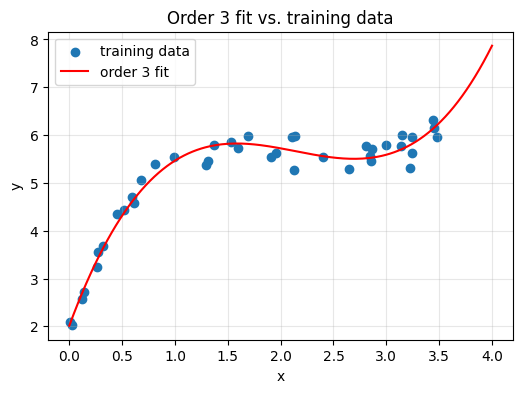

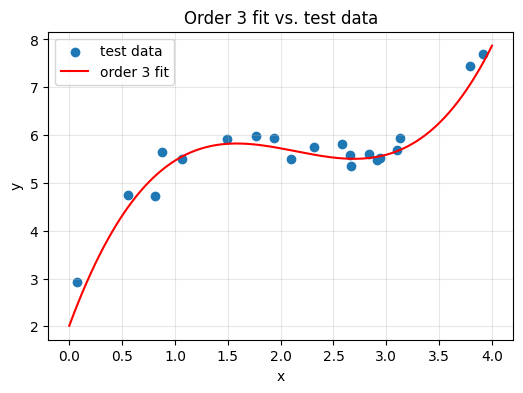

In [19]:
order = 3

Xtr, Xte = design_matrix(xtr, order), design_matrix(xte, order)
w3 = fit_linear_regression(Xtr, ytr)           # fit on TRAINING data only
train_err3 = avg_error(Xtr, ytr, w3)
test_err3 = avg_error(Xte, yte, w3)

print("weights:", w3)
print(f"order 3: train error = {train_err3:.4f},  test error = {test_err3:.4f}")

plot_fit(xtr, ytr, w3, order, title="Order 3 fit vs. training data", label="training data")
plot_fit(xte, yte, w3, order, title="Order 3 fit vs. test data", label="test data")

**Answer:**

| Model | Train error | Test error |
|---|---|---|
| Linear (order 1) | 0.5086 | 0.4439 |
| Quadratic (order 2) | 0.2010 | 0.8533 |
| Cubic (order 3) | 0.0392 | 0.0564 |

Yes. The cubic is better than both on **both** sets: training error 0.0392 (vs 0.5086 and 0.2010) and test error 0.0564 (vs 0.4439 and 0.8533). The data has a rise-then-flatten shape that a cubic can represent, and the cubic's test error is close to its training error, so it generalizes well.

### 2(f) &nbsp; [10 points]
Implement **4th-order** polynomial regression by adding features $x^2, x^3, x^4$. Repeat (b) and (c).
Compare with the previous results. Which order is best for fitting the data?

weights: [ 1.8964  6.7994 -4.1019  0.964  -0.071 ]
order 4: train error = 0.0356,  test error = 0.1272


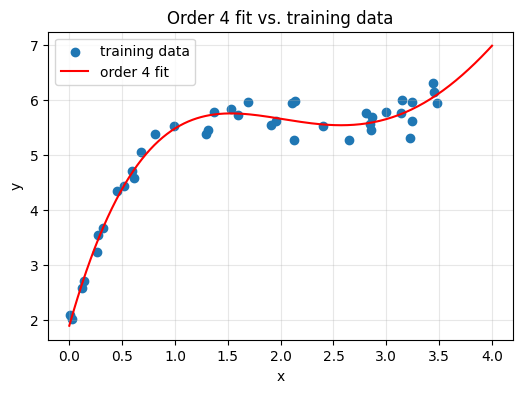

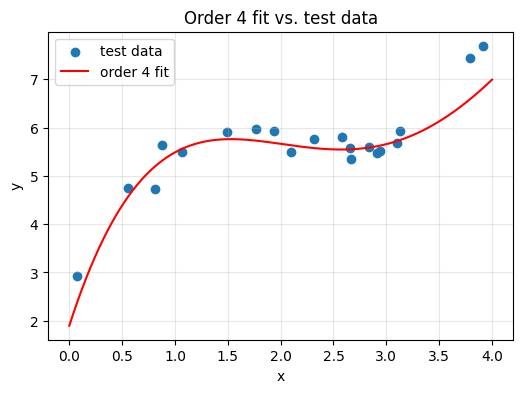

In [20]:
order = 4

Xtr, Xte = design_matrix(xtr, order), design_matrix(xte, order)
w4 = fit_linear_regression(Xtr, ytr)           # fit on TRAINING data only
train_err4 = avg_error(Xtr, ytr, w4)
test_err4 = avg_error(Xte, yte, w4)

print("weights:", w4)
print(f"order 4: train error = {train_err4:.4f},  test error = {test_err4:.4f}")

plot_fit(xtr, ytr, w4, order, title="Order 4 fit vs. training data", label="training data")
plot_fit(xte, yte, w4, order, title="Order 4 fit vs. test data", label="test data")

**Summary table & answer:**

| Order | Train error | Test error |
|---|---|---|
| 1 | 0.5086 | 0.4439 |
| 2 | 0.2010 | 0.8533 |
| 3 | 0.0392 | **0.0564** |
| 4 | **0.0356** | 0.1272 |


The quartic has the lowest training error (0.0356), but only slightly lower than the cubic's 0.0392, while its test error more than doubles (0.0564 -> 0.1272). The extra flexibility is fitting noise in the training set, which is overfitting. **The 3rd-order polynomial is the best fit**, since it has the lowest test error.

---
## 3. Regularization and Cross-Validation
**[25 points]**

### 3(a) &nbsp; [10 points]
Using the training data, implement $\ell_2$-regularized **4th-order** polynomial regression (Lecture 4, p.12; **do not penalize the bias $w_0$**).
Vary $\lambda\in\{0.01,\,0.05,\,0.1,\,0.5,\,1,\,100,\,10^5\}$.
Plot training and test error (averaged over all instances, Eq. 1) as a function of $\lambda$ using a $\log_{10}$ scale for $\lambda$.

Which $\lambda$ is best for fitting the training data? Which is best for the test data?

> Note: the PDF text extracts the last value as "105", which I read as $10^5$. Verify against the original PDF.

In [21]:
lambdas = [0.01, 0.05, 0.1, 0.5, 1, 100, 1e5]

# TODO: for each lambda fit ridge on training data (order 4), store weights + train/test error
# TODO: plot errors vs log10(lambda)

**Answer:**

_TODO_

### 3(b) &nbsp; [10 points]
Plot the value of each weight parameter (including the bias $w_0$) as a function of $\lambda$.

In [22]:
# TODO: one curve per weight w0..w4 vs log10(lambda)

**Answer / observations:**

_TODO_

### 3(c) &nbsp; [5 points]
Write a procedure that performs **five-fold cross-validation** on the training data (Lecture 4, p.7) and use it to pick the best $\lambda$.
Show the average validation error as a function of $\lambda$. Is the best $\lambda$ the same as in (a)?
For the best fit, plot the test data and the $\ell_2$-regularized 4th-order regression line.

In [23]:
def cross_validate(x, y, lam, order=4, k=5):
    '''Return the mean validation error of k-fold CV for one lambda.'''
    # TODO
    raise NotImplementedError

In [24]:
# TODO: cv_errors = [cross_validate(xtr, ytr, lam) for lam in lambdas]
# TODO: plot CV error vs log10(lambda); pick best_lam
# TODO: refit on all training data with best_lam, plot fit over test data

**Answer:**

_TODO_